# A two-line model for chunk read cost

We approximate measured chunk read cost with a continuous two-line model and evaluate it on held-out repeats.

In [1]:
from pathlib        import Path
from scipy.optimize import nnls 
from dataclasses    import dataclass

import json
import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt

In [2]:
CSV_PATH = Path("chunk_latency_measurements.csv")

## 1. Measured curve

[01_01](01_01_measure_chunk_latency.ipynb) records amortized batch cost in `chunk_latency_measurements.csv`. Let $\mathcal G$ be its chunk-size grid in KiB and $T(z)$ the median cost in ms over all seven repeats.

Repeats 0–3 define the training median $T_{\mathrm{train}}$; repeats 4–6 define the test median $T_{\mathrm{test}}$. All coefficients and boundary choices use training repeats only.

In [3]:
measurements = pd.read_csv(CSV_PATH)
measurements.head()

,repeat,order,size_kib,latency_ms,throughput_mib_s
0,0,0,348,0.117393,2894.935742
1,0,1,524,0.184180,2778.360944
2,0,2,146,0.070203,2030.946647
3,0,3,149,0.072297,2012.628482
4,0,4,196,0.084002,2278.584632


In [4]:
sizes   = np.sort(measurements["size_kib"].unique()) # KiB, (432,)
repeats = np.sort(measurements["repeat"]  .unique()) #      (  7,)

latency_table = (
    measurements.pivot(
        index   = "size_kib",
        columns = "repeat",
        values  = "latency_ms",
    )
    .sort_index()
    .sort_index(axis=1)
    .to_numpy(float)
) # (432, 7)

latencies = np.median(latency_table, axis=1) #  ms, (432,)


In [5]:
train_repeats = repeats[:4].tolist() # 4 repeats
test_repeats  = repeats[4:].tolist() # 3 repeats

train_latencies = np.median(latency_table[:,  :4], axis=1) # ms, (432,)
test_latencies  = np.median(latency_table[:, 4: ], axis=1) # ms, (432,)

### Characteristic sizes

Throughput derived from the training median is

$$\beta_{\mathrm{train}}(z)=\frac{1000z}{1024T_{\mathrm{train}}(z)}\quad\mathrm{MiB/s}.$$

Its peak defines the most efficient measured size:

$$z_{\rm eff}\in\arg\max_{z\in\mathcal G}\beta_{\mathrm{train}}(z).$$

After a centered three-point median, the first size reaching 99% of peak throughput is

$$z_{99}=\min\left\{z\in\mathcal G:\widetilde\beta_{\mathrm{train}}(z)
\ge0.99\max_{u\in\mathcal G}\widetilde\beta_{\mathrm{train}}(u)\right\}.$$

These summarize the measured curve; the fitted boundary below minimizes model error.

In [6]:
# throughputs derived from median latencies (MiB/s), shape (432,).
throughputs       = 1000 * sizes / (1024 * latencies)
train_throughputs = 1000 * sizes / (1024 * train_latencies)
test_throughputs  = 1000 * sizes / (1024 * test_latencies)

# peak throughput size (from training repeats)
peak_throughput_size = sizes[np.argmax(train_throughputs)]

In [7]:
# centered three-point median of training throughput (MiB/s).
train_smoothed_throughputs = (
    pd.Series(train_throughputs)
    .rolling(3, center=True, min_periods=1)
    .median()
    .to_numpy()
)

# first size reaching 99% of 
# peak smoothed training throughput.
throughput_99pct_size = sizes[
    np.flatnonzero(
        train_smoothed_throughputs >= .99 * train_smoothed_throughputs.max()
    )[0]
]

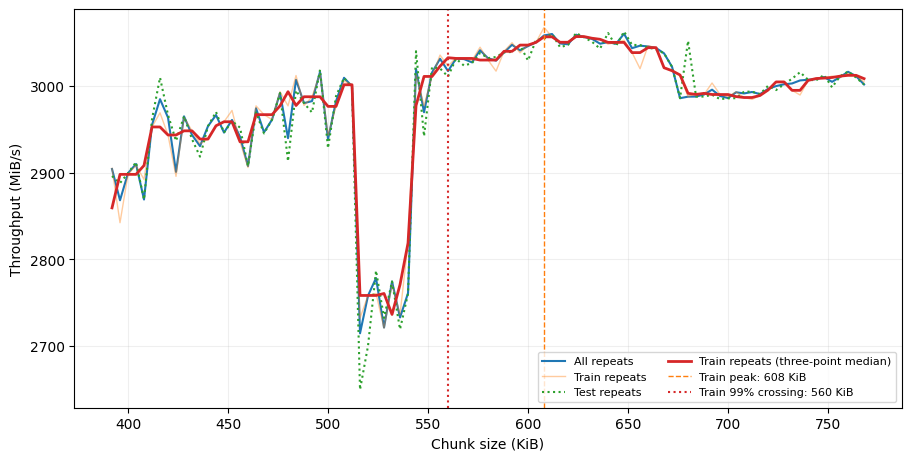

In [8]:
mask = (
    sizes >= 0.7 * min(peak_throughput_size, throughput_99pct_size)
)

fig, ax = plt.subplots(
    figsize = (9, 4.5),
    layout  = "constrained",
)

# --------------------------------

# throughputs
ax.plot(
    # data
    sizes[mask],
    throughputs[mask],
    label = "All repeats",
    
    # style
    color     = "tab:blue",
    linewidth = 1.5,
)

# train throughputs
ax.plot(
    # data
    sizes[mask],
    train_throughputs[mask],
    label = "Train repeats",

    # style
    color     = "tab:orange",
    alpha     = 0.4,
    linewidth = 1,
)

# test throughputs
ax.plot(
    # data
    sizes[mask],
    test_throughputs[mask],
    label = "Test repeats",

    # style
    color     = "tab:green",
    linestyle = ":",
    linewidth = 1.5,
)

# smoothed training throughputs
ax.plot(
    # data
    sizes[mask],
    train_smoothed_throughputs[mask],
    label = "Train repeats (three-point median)",

    # style
    color     = "tab:red",
    linewidth = 2,
)

# --------------------------------

# peak throughput size
ax.axvline(
    # data
    peak_throughput_size,
    label = f"Train peak: {peak_throughput_size:g} KiB",

    # style
    color     = "tab:orange",
    linestyle = "--",
    linewidth = 1,
)

# throughput 99pct size
ax.axvline(
    # data
    throughput_99pct_size,
    label = f"Train 99% crossing: {throughput_99pct_size:g} KiB", 

    # style
    color     = "tab:red",
    linestyle = ":",
    linewidth = 1.5,
)

# --------------------------------

ax.set(
    xlabel = "Chunk size (KiB)",
    ylabel = "Throughput (MiB/s)",
)

ax.legend(
    fontsize = 8, 
    ncol     = 2, 
    loc      = "lower right"
)

ax.grid(alpha=0.2)
plt.show()

## 2. Model fitting

We fit the two-line model

$$T_{\rm 2L}(z;z_0)=bz+\delta\max(z_0,z),\qquad b,\delta\ge0.$$

Beyond $z_0$, cost per KiB is constant at $b+\delta$. This is a model assumption.

For each $z_0\in\mathcal G$, nonnegative least squares fits $b$ and $\delta$. The free boundary $z_{\rm 2L}$ minimizes training RMSE. Every measured size has equal weight, so the denser grid through 320 KiB contributes more observations.

Two baselines are an unconstrained continuous hinge and an affine model:

$$T_{\rm H}(z)=a+bz+\delta(z-z_0)_+,\qquad T_{\rm A}(z)=a+bz,$$

where $(x)_+=\max(x,0)$. The hinge boundary minimizes the same training loss. We also fit the two-line model at $z_{\rm eff}$, $z_{99}$, and the hinge boundary.

In [9]:
@dataclass(frozen=True)
class LatencyFit:
    """A continuous curve described by an intercept, slope, and slope change."""

    intercept    : float
    short_slope  : float
    slope_change : float
    boundary     : float = 0.0

    def predict(self, sizes):
        sizes = np.asarray(sizes, dtype=float)

        return (
            self.intercept
            + self.short_slope * sizes
            + self.slope_change * np.maximum(sizes - self.boundary, 0)
        )


def rmse(observed, predicted):
    return np.sqrt(np.mean((observed - predicted) ** 2))

In [10]:
def fit_two_line(sizes, latencies, *, boundary):
    
    """Fit a zero-intercept tail with nonnegative short_slope and slope_change."""

    design = np.column_stack((
        sizes,
        np.maximum(boundary, sizes),
    ))
    
    short_slope, slope_change =\
          nnls(design, latencies)[0]

    return LatencyFit(
        intercept    = slope_change * boundary,
        short_slope  = short_slope,
        slope_change = slope_change,
        boundary     = boundary,
    )

In [11]:
def fit_hinge(sizes, latencies, *, boundary):
    
    """Fit an unconstrained continuous pair of lines."""
    
    design = np.column_stack((
        np.ones_like(sizes),
        sizes,
        np.maximum(sizes - boundary, 0),
    ))
    
    intercept, short_slope, slope_change =\
          np.linalg.lstsq(design, latencies, rcond=None)[0]

    return LatencyFit(
        intercept    = intercept,
        short_slope  = short_slope,
        slope_change = slope_change,
        boundary     = boundary,
    )

In [12]:
def fit_affine(sizes, latencies):

    """Fit a single line with a free intercept."""
    
    design = np.column_stack((
        np.ones_like(sizes), 
        sizes
    ))
    
    intercept, slope =\
        np.linalg.lstsq(design, latencies, rcond=None)[0]

    return LatencyFit(
        intercept    = intercept,
        short_slope  = slope,
        slope_change = 0.0,
    )

In [13]:
def fit_boundaries(fitter, sizes, latencies):
    """Return fitted models and training RMSE keyed by boundary size."""
    fits   = {}
    errors = {}

    for boundary in sizes:

        # latency model & its error
        fits  [boundary] = fit = fitter(sizes, latencies, boundary=boundary)
        errors[boundary]       = rmse(latencies, fit.predict(sizes))

    return fits, errors

In [14]:
two_line_fits, two_line_errors = fit_boundaries(
    fit_two_line, sizes, train_latencies,
)

hinge_fits, hinge_errors = fit_boundaries(
    fit_hinge, sizes, train_latencies,
)

affine = fit_affine(sizes, train_latencies)
affine_error = rmse(train_latencies, affine.predict(sizes))

In [15]:
two_line_boundary = min(two_line_errors, key = two_line_errors.get)
hinge_boundary    = min(   hinge_errors, key =    hinge_errors.get)

In [16]:
boundaries = [
    peak_throughput_size,
    throughput_99pct_size,
    two_line_boundary,
    hinge_boundary,
]

mask = (min(boundaries) - 50 < sizes) & (sizes < max(boundaries) + 50)

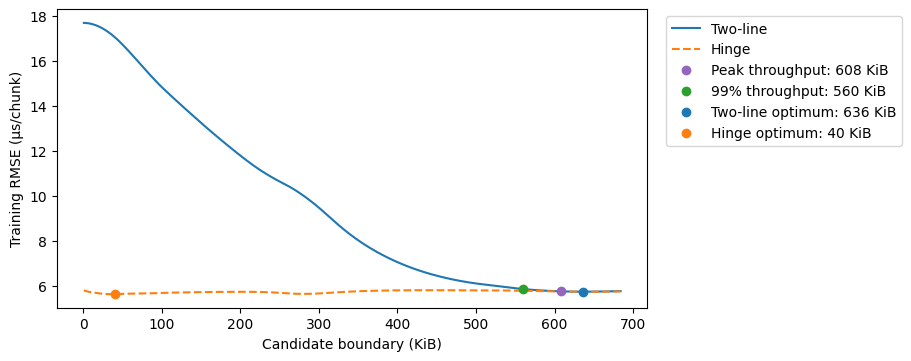

In [17]:
fig, ax = plt.subplots(
    figsize=(9, 3.5),
    layout="constrained",
)

# Step 1. draw training error across candidate boundaries

ax.plot(
    sizes[mask],
    1000 * np.array([two_line_errors[size] for size in sizes[mask]]),
    label = "Two-line",
)
ax.plot(
    sizes[mask],
    1000 * np.array([hinge_errors[size] for size in sizes[mask]]),
    linestyle = "--",
    label     = "Hinge",
)

# Step 2. mark selected boundaries on the two-line curve

two_line_boundaries = [
    ( "Peak throughput",  peak_throughput_size, "tab:purple"),
    (  "99% throughput", throughput_99pct_size, "tab:green"),
    ("Two-line optimum",     two_line_boundary, "tab:blue"),
]

for name, boundary, color in two_line_boundaries:
    ax.plot(
        boundary,
        1000 * two_line_errors[boundary],
        "o",
        color=color,
        label=f"{name}: {boundary:g} KiB",
    )

# Step 3. mark the optimum on the hinge curve

ax.plot(
    hinge_boundary,
    1000 * hinge_errors[hinge_boundary],
    "o",
    color="tab:orange",
    label=f"Hinge optimum: {hinge_boundary:g} KiB",
)

# Finish

ax.set(
    xlabel = "Candidate boundary (KiB)",
    ylabel = "Training RMSE (µs/chunk)",
)
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)

plt.show()

/tmp/ipykernel_3734028/1917985398.py:10: RuntimeWarning: divide by zero encountered in scalar divide
  [two_line_fits[size].slope_change / two_line_fits[size].short_slope


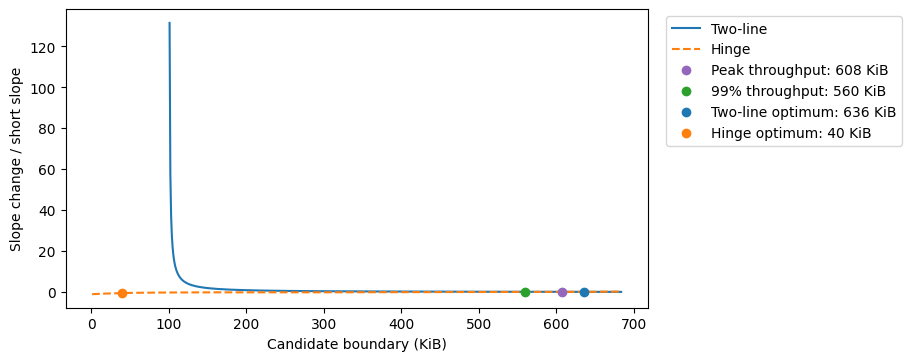

In [18]:
fig, ax = plt.subplots(
    figsize=(9, 3.5),
    layout="constrained",
)

# Step 1. draw relative slope changes across candidate boundaries

ax.plot(
    sizes[mask],
    [two_line_fits[size].slope_change / two_line_fits[size].short_slope
     for size in sizes[mask]],
    label = "Two-line",
)
ax.plot(
    sizes[mask],
    [hinge_fits[size].slope_change / hinge_fits[size].short_slope
     for size in sizes[mask]],
    linestyle = "--",
    label     = "Hinge",
)

# Step 2. mark selected boundaries on the two-line curve

two_line_boundaries = [
    ( "Peak throughput",  peak_throughput_size, "tab:purple"),
    (  "99% throughput", throughput_99pct_size, "tab:green"),
    ("Two-line optimum",     two_line_boundary, "tab:blue"),
]

for name, boundary, color in two_line_boundaries:
    fit = two_line_fits[boundary]
    ax.plot(
        boundary,
        fit.slope_change / fit.short_slope,
        "o",
        color=color,
        label=f"{name}: {boundary:g} KiB",
    )

# Step 3. mark the optimum on the hinge curve

fit = hinge_fits[hinge_boundary]
ax.plot(
    hinge_boundary,
    fit.slope_change / fit.short_slope,
    "o",
    color="tab:orange",
    label=f"Hinge optimum: {hinge_boundary:g} KiB",
)

# Finish

ax.set(
    xlabel = "Candidate boundary (KiB)",
    ylabel = "Slope change / short slope",
)
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)

plt.show()

In [19]:
models = {
    
    # two lines
    "Two-line (free)"           : two_line_fits[two_line_boundary],
    "Two-line (efficiency)"     : two_line_fits[peak_throughput_size],
    "Two-line (99%)"            : two_line_fits[throughput_99pct_size],
    "Two-line (hinge boundary)" : two_line_fits[hinge_boundary],
    
    # hinge
    "Hinge": hinge_fits[hinge_boundary],
    
    # affine
    "Affine": affine,
}


In [20]:
parameter_rows = {}

for name, fit in models.items():
    parameter_rows[name] = {
        "Boundary (KiB)"         : fit.boundary,
        "Intercept (µs)"         : 1000 * fit.intercept,
        "Short slope (µs/KiB)"   : 1000 * fit.short_slope,
        "Slope change (µs/KiB)"  : 1000 * fit.slope_change,
        "Slope change / short"   : fit.slope_change / fit.short_slope,
    }

pd.DataFrame.from_dict(parameter_rows, orient="index").round(6)

/tmp/ipykernel_3734028/2105595323.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  "Slope change / short"   : fit.slope_change / fit.short_slope,


,Boundary (KiB),Intercept (µs),Short slope (µs/KiB),Slope change (µs/KiB),Slope change / short
Two-line (free),636.0,28.107470,0.280310,0.044194,0.157662
Two-line (efficiency),608.0,28.315551,0.278994,0.046572,0.166927
Two-line (99%),560.0,28.738715,0.276047,0.051319,0.185907
Two-line (hinge boundary),40.0,14.015779,0.000000,0.350394,inf
Hinge,40.0,19.652736,0.506571,-0.226085,-0.446306
Affine,0.0,27.618587,0.283056,0.000000,0.000000


## 3. Held-out error

We evaluate the fitted curves against $T_{\mathrm{test}}$ across all measured sizes, reporting RMSE in µs and MAPE in percent. Residuals are prediction minus held-out cost.

In [21]:
evaluation_rows = {}

for name, fit in models.items():

    # predict latency
    predicted = fit.predict(sizes)

    # relative errors -> MAPE
    relative_errors = np.abs(predicted - test_latencies) / test_latencies

    # compair with test latency
    evaluation_rows[name] = {
        "Train RMSE (µs)" : 1000 * rmse(train_latencies, predicted),
         "Test RMSE (µs)" : 1000 * rmse( test_latencies, predicted),
          "Test MAPE (%)" : 100 * np.mean(relative_errors),
    }

pd.DataFrame.from_dict(evaluation_rows, orient="index").round(3)

,Train RMSE (µs),Test RMSE (µs),Test MAPE (%)
Two-line (free),5.735,5.967,5.281
Two-line (efficiency),5.748,5.986,5.322
Two-line (99%),5.852,6.098,5.445
Two-line (hinge boundary),17.066,17.229,22.697
Hinge,5.624,5.844,4.537
Affine,5.800,6.020,5.261


In [22]:
plot_models = {
    "Two-line (efficiency)": "-",
    "Two-line (free)": "--",
    "Hinge": "-.",
    "Affine": ":",
}

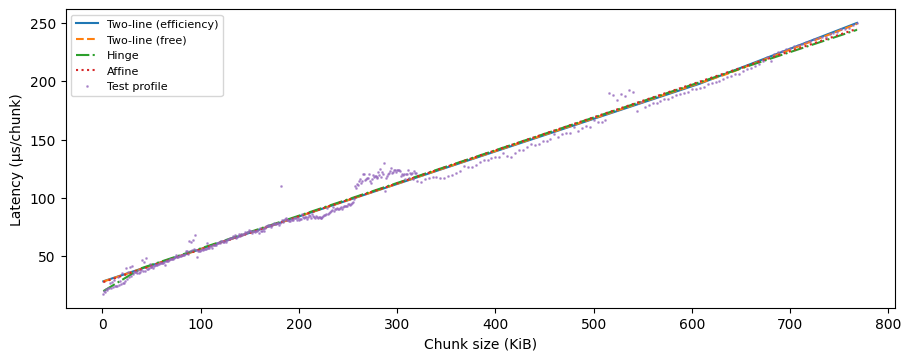

In [23]:
fig, ax = plt.subplots(
    figsize=(9, 3.5),
    layout="constrained",
)

# Model predictions
for name, style in plot_models.items():
    predicted = models[name].predict(sizes)
    ax.plot(
        sizes, 
        1000 * predicted, 
        style, 
        label=name
    )

# Held-out measurements
ax.plot(
    sizes,
    1000 * test_latencies, 
    ".",
    markersize = 2,
    alpha      = 0.6,
    label      = "Test profile",
)

ax.set(
    xlabel = "Chunk size (KiB)",
    ylabel = "Latency (µs/chunk)",
)
ax.legend(fontsize=8)
plt.show()

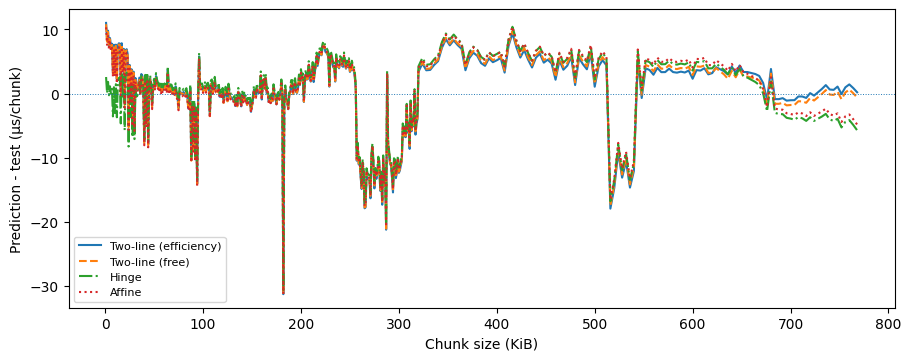

In [24]:
fig, ax = plt.subplots(
    figsize=(9, 3.5),
    layout="constrained",
)

# Model residuals
for name, style in plot_models.items():
    residuals = models[name].predict(sizes) - test_latencies
    ax.plot(
        sizes,
        1000 * residuals,
        style,
        label=name,
    )

# Zero-error reference
ax.axhline(0, linestyle=":", linewidth=0.7)

ax.set(
    xlabel="Chunk size (KiB)",
    ylabel="Prediction - test (µs/chunk)",
)
ax.legend(fontsize=8, loc="lower left")
plt.show()

## 4. Additive mask cost

The hinge has the lowest held-out error. We use the two-line model in the subsequent optimization because its cost separates as

$$T_{\rm 2L}(z)=(b+\delta)z+\delta(z_{\rm 2L}-z)_+.$$

Let $M$ be the selected rows, $\mathcal C(M)$ their maximal contiguous runs, and $q$ the row length in KiB. Summing over runs gives

$$\boxed{L_{\rm 2L}(M)=(b+\delta)q|M|
+\delta\sum_{C\in\mathcal C(M)}(z_{\rm 2L}-q|C|)_+.}$$

At a fixed row count, the first term is constant. The second penalizes short runs. Complete-mask latency and extrapolation beyond the measured sizes require separate validation.

Save the fitted models to `latency_model.json`. Experiment 02 uses `Two-line (free)`; `s99_kib` sets the Paper selector window limit.

In [25]:
exported_models = {}

for name, fit in models.items():

    # metadata of each model
    exported_models[name] = {
        "boundary_kib"            : float(fit.boundary),
        "intercept_ms"            : float(fit.intercept),
        "short_slope_ms_per_kib"  : float(fit.short_slope),
        "slope_change_ms_per_kib" : float(fit.slope_change),
    }

In [26]:
model_data = {
    "models"  : exported_models,
    "s99_kib" : float(throughput_99pct_size),
}

In [27]:
model_path = CSV_PATH.with_name("latency_model.json")

model_path.write_text(
    json.dumps(model_data, indent=2), 
    encoding="utf-8",
)

1289